# Hydraulic Dataset — Data Processing Notebook (CORRECTED)

This notebook prepares the UCI Condition Monitoring of Hydraulic Systems dataset for ML training.

**Key Corrections in this version:**
1. ✅ **Stratified Split** instead of Chronological split (so all classes appear in Train/Val/Test)
2. ✅ **EDA added** with box plots showing sensor behavior across health conditions
3. ✅ **Correlation heatmap** for key sensors
4. ✅ Proper class coverage reporting

## 1. Install and import libraries

In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 2. Upload or locate the hydraulic dataset

In [3]:
DATA_DIR = Path("/content/data/raw/hydraulic")

if (Path("/content") / "PS1.txt").exists():
    DATA_DIR = Path("/content")

print("Current DATA_DIR:", DATA_DIR)
print("Directory exists:", DATA_DIR.exists())

Current DATA_DIR: /content/data/raw/hydraulic
Directory exists: False


In [4]:
from google.colab import files
import zipfile

if not (DATA_DIR / "PS1.txt").exists():
    uploaded = files.upload()
    uploaded_names = list(uploaded.keys())
    zip_name = next((name for name in uploaded_names if name.lower().endswith(".zip")), None)

    if zip_name:
        extract_root = Path("/content/data/raw")
        extract_root.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_name) as archive:
            archive.extractall(extract_root)
        candidates = [extract_root / "hydraulic", extract_root]
        for candidate in candidates:
            if (candidate / "PS1.txt").exists():
                DATA_DIR = candidate
                break
    else:
        DATA_DIR = Path("/content")

print("Using:", DATA_DIR)
print("TXT files:", len(list(DATA_DIR.glob("*.txt"))))

Saving condition+monitoring+of+hydraulic+systems.zip to condition+monitoring+of+hydraulic+systems.zip
Using: /content/data/raw
TXT files: 20


## 3. Validate required files

In [5]:
SENSOR_FILES = [
    "PS1.txt", "PS2.txt", "PS3.txt", "PS4.txt", "PS5.txt", "PS6.txt",
    "TS1.txt", "TS2.txt", "TS3.txt", "TS4.txt",
    "FS1.txt", "FS2.txt", "VS1.txt",
    "CE.txt", "CP.txt", "SE.txt", "EPS1.txt",
]
REQUIRED_FILES = SENSOR_FILES + ["profile.txt"]
missing_files = [name for name in REQUIRED_FILES if not (DATA_DIR / name).exists()]

if missing_files:
    print("Missing files:", missing_files)
    raise FileNotFoundError("Upload all required hydraulic sensor files and profile.txt.")

print(f"Validation passed: {len(SENSOR_FILES)} sensor files + profile.txt found.")

Validation passed: 17 sensor files + profile.txt found.


## 4. Load the target profile

In [6]:
def read_numeric_table(path: Path) -> pd.DataFrame:
    """Read a whitespace/comma table and keep rows containing numeric values."""
    table = pd.read_csv(path, sep=r"\s+", header=None, engine="python")
    if table.shape[1] == 1:
        fallback = pd.read_csv(path, sep=",", header=None, engine="python")
        if fallback.shape[1] > 1:
            table = fallback
    numeric = table.apply(pd.to_numeric, errors="coerce")
    numeric = numeric.dropna(axis=0, how="all").dropna(axis=1, how="all")
    return numeric.reset_index(drop=True)

profile_raw = read_numeric_table(DATA_DIR / "profile.txt")
print("Profile shape:", profile_raw.shape)
display(profile_raw.head())

Profile shape: (2205, 5)


,0,1,2,3,4
0,3,100,0,130,1
1,3,100,0,130,1
2,3,100,0,130,1
3,3,100,0,130,1
4,3,100,0,130,1


In [7]:
TARGET_NAMES = [
    "cooler_condition",
    "valve_condition",
    "pump_leakage",
    "accumulator_pressure",
]

if profile_raw.shape[1] < 4:
    raise ValueError(
        f"profile.txt has only {profile_raw.shape[1]} numeric columns; "
        "at least four target columns are expected."
    )

profile = profile_raw.iloc[:, :4].copy()
profile.columns = TARGET_NAMES
print("Target columns:", list(profile.columns))
for target in TARGET_NAMES:
    print(target, "classes:", sorted(profile[target].dropna().unique().tolist()))

display(profile.head())

Target columns: ['cooler_condition', 'valve_condition', 'pump_leakage', 'accumulator_pressure']
cooler_condition classes: [3, 20, 100]
valve_condition classes: [73, 80, 90, 100]
pump_leakage classes: [0, 1, 2]
accumulator_pressure classes: [90, 100, 115, 130]


,cooler_condition,valve_condition,pump_leakage,accumulator_pressure
0,3,100,0,130
1,3,100,0,130
2,3,100,0,130
3,3,100,0,130
4,3,100,0,130


## 5. Load raw sensor files

In [8]:
def load_sensor_file(filename: str) -> pd.DataFrame:
    path = DATA_DIR / filename
    table = read_numeric_table(path)
    sensor_name = path.stem
    table.columns = [f"{sensor_name}_{i}" for i in range(table.shape[1])]
    return table

sensor_tables = {name: load_sensor_file(name) for name in SENSOR_FILES}
row_counts = {name: len(table) for name, table in sensor_tables.items()}
print("Sensor row counts:")
display(pd.Series(row_counts, name="rows").to_frame().T)
print("Profile rows:", len(profile))

Sensor row counts:


,PS1.txt,PS2.txt,PS3.txt,PS4.txt,PS5.txt,PS6.txt,TS1.txt,TS2.txt,TS3.txt,TS4.txt,FS1.txt,FS2.txt,VS1.txt,CE.txt,CP.txt,SE.txt,EPS1.txt
rows,2205,2205,2205,2205,2205,2205,2205,2205,2205,2205,2205,2205,2205,2205,2205,2205,2205


Profile rows: 2205


In [9]:
all_lengths = list(row_counts.values()) + [len(profile)]
if len(set(all_lengths)) != 1:
    print("Different row counts found. Aligning to shortest length.")
    print("Shortest length:", min(all_lengths))
else:
    print("All files have the same number of cycle rows.")

N_CYCLES = min(all_lengths)
sensor_tables = {name: table.iloc[:N_CYCLES].reset_index(drop=True) for name, table in sensor_tables.items()}
profile = profile.iloc[:N_CYCLES].reset_index(drop=True)

All files have the same number of cycle rows.


## 6. Extract cycle-level features

In [10]:
def summarize_sensor(sensor_name: str, table: pd.DataFrame) -> pd.DataFrame:
    """Convert each sensor's time-window row into one feature row per cycle."""
    return pd.DataFrame({
        f"{sensor_name}_mean": table.mean(axis=1),
        f"{sensor_name}_std": table.std(axis=1),
        f"{sensor_name}_min": table.min(axis=1),
        f"{sensor_name}_max": table.max(axis=1),
        f"{sensor_name}_median": table.median(axis=1),
    })

feature_frames = [summarize_sensor(name.removesuffix(".txt"), table)
                  for name, table in sensor_tables.items()]
features = pd.concat(feature_frames, axis=1)
features.insert(0, "cycle_id", np.arange(len(features)))

processed = pd.concat([features, profile], axis=1)
print("Processed shape:", processed.shape)
display(processed.head())

Processed shape: (2205, 90)


,cycle_id,PS1_mean,PS1_std,PS1_min,PS1_max,PS1_median,PS2_mean,PS2_std,PS2_min,PS2_max,...,SE_median,EPS1_mean,EPS1_std,EPS1_min,EPS1_max,EPS1_median,cooler_condition,valve_condition,pump_leakage,accumulator_pressure
0,0,160.673492,13.939309,145.83,191.51,156.25,109.466914,47.114508,0.0,156.99,...,68.5145,2538.929167,185.616121,2339.8,2951.6,2479.8,3,100,0,130
1,1,160.603320,14.118967,145.73,191.47,156.06,109.354890,47.045611,0.0,157.56,...,68.5360,2531.498900,189.940089,2332.0,2947.4,2470.0,3,100,0,130
2,2,160.347720,14.192619,145.37,191.41,155.72,109.158845,46.992060,0.0,156.97,...,68.8530,2519.928000,190.736850,2318.6,2939.8,2457.4,3,100,0,130
3,3,160.188088,14.227803,145.14,191.34,155.56,109.064807,46.972221,0.0,156.44,...,69.0060,2511.541633,191.270607,2310.8,2929.6,2448.0,3,100,0,130
4,4,160.000472,14.276434,144.95,191.41,155.34,108.931434,46.874946,0.0,158.13,...,69.0130,2503.449500,191.258369,2301.8,2923.8,2440.6,3,100,0,130


## 7. EDA — Exploratory Data Analysis ✨ NEW

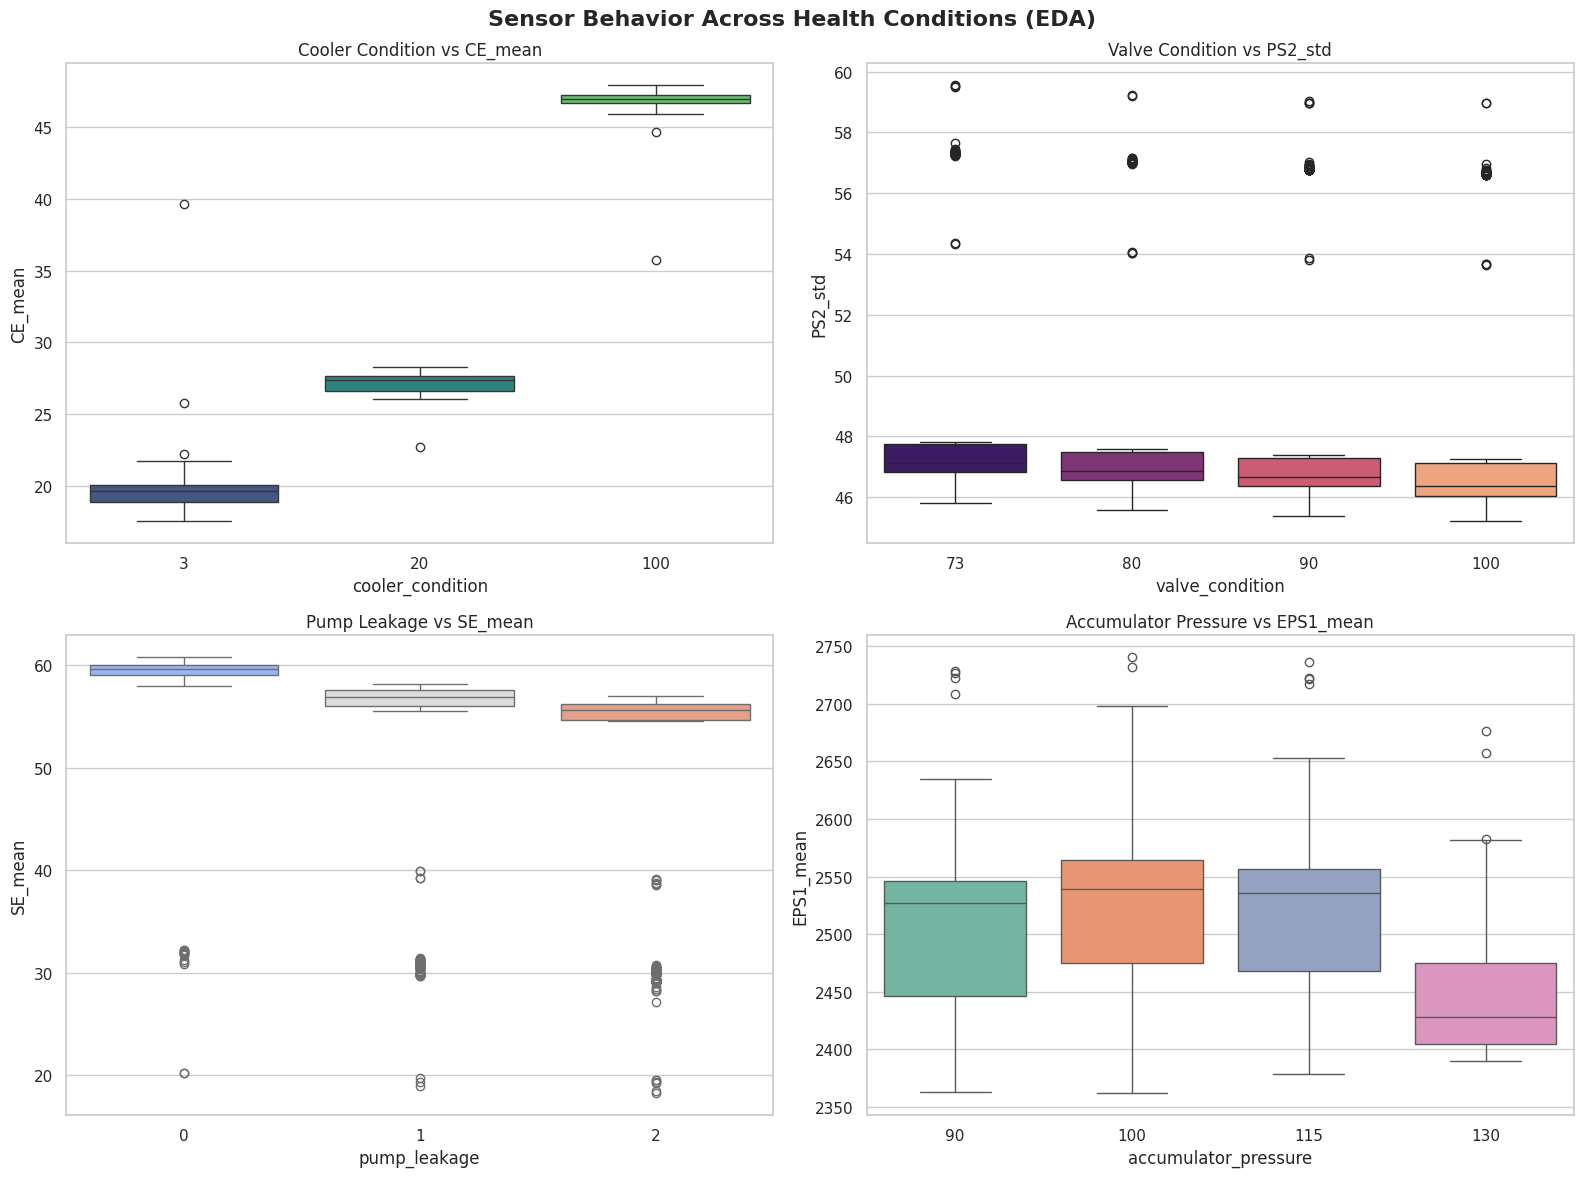

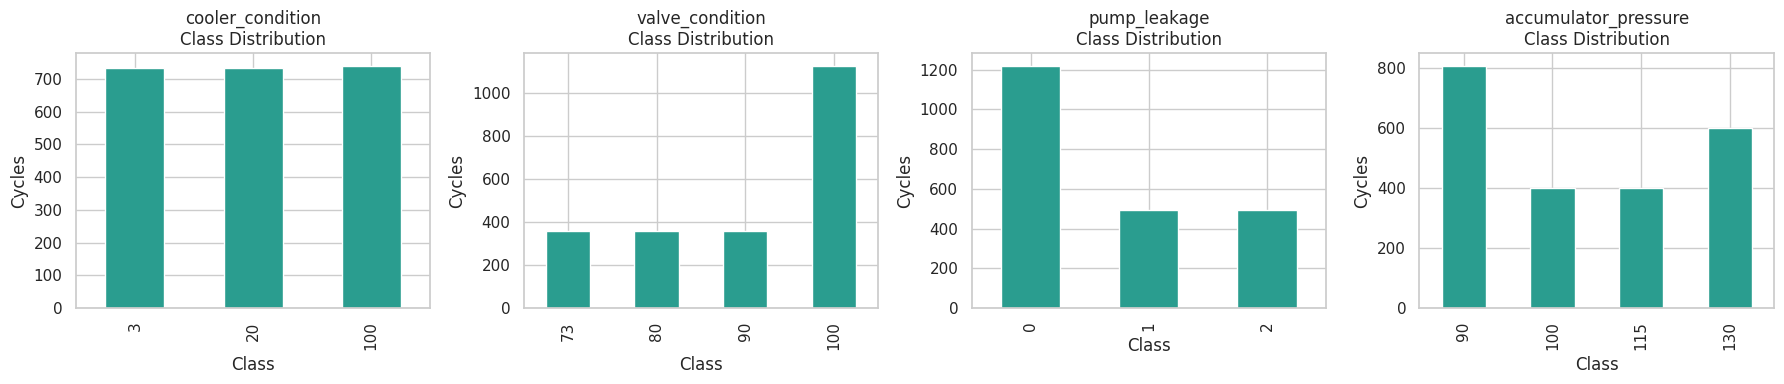

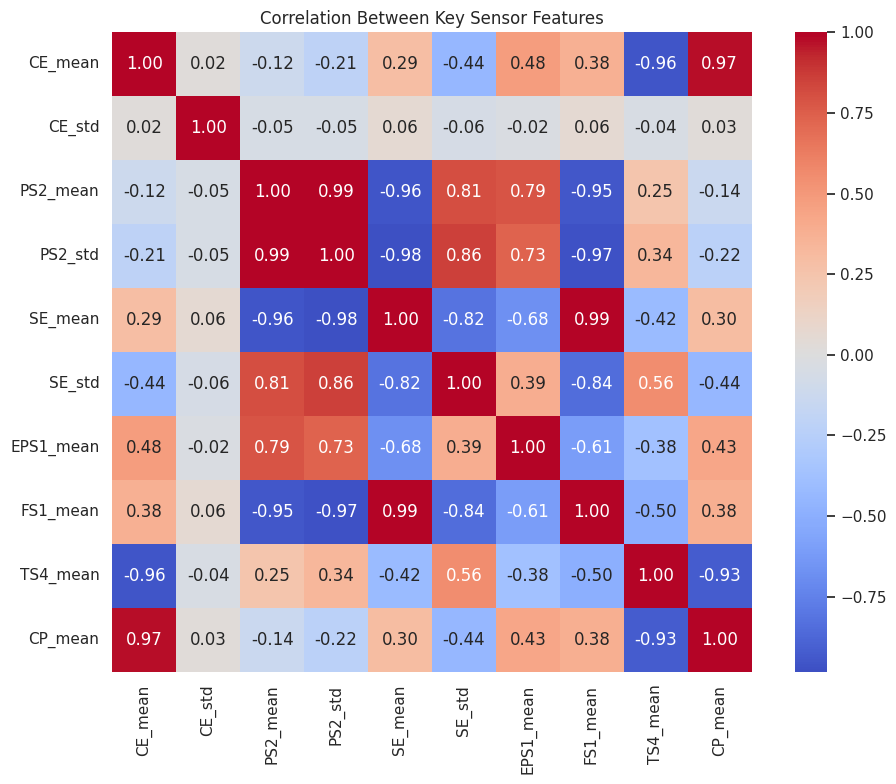

In [11]:
# Sensor behavior across health conditions
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Sensor Behavior Across Health Conditions (EDA)", fontsize=16, fontweight="bold")

sns.boxplot(data=processed, x="cooler_condition", y="CE_mean", ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title("Cooler Condition vs CE_mean")

sns.boxplot(data=processed, x="valve_condition", y="PS2_std", ax=axes[0, 1], palette="magma")
axes[0, 1].set_title("Valve Condition vs PS2_std")

sns.boxplot(data=processed, x="pump_leakage", y="SE_mean", ax=axes[1, 0], palette="coolwarm")
axes[1, 0].set_title("Pump Leakage vs SE_mean")

sns.boxplot(data=processed, x="accumulator_pressure", y="EPS1_mean", ax=axes[1, 1], palette="Set2")
axes[1, 1].set_title("Accumulator Pressure vs EPS1_mean")

plt.tight_layout()
plt.show()

# Target distribution
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, target in zip(axes, TARGET_NAMES):
    processed[target].value_counts().sort_index().plot(kind="bar", ax=ax, color="#2a9d8f")
    ax.set_title(f"{target}\nClass Distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Cycles")
plt.tight_layout()
plt.show()

# Correlation heatmap
top_sensors = ["CE_mean", "CE_std", "PS2_mean", "PS2_std", "SE_mean", "SE_std",
               "EPS1_mean", "FS1_mean", "TS4_mean", "CP_mean"]
available_sensors = [s for s in top_sensors if s in processed.columns]
plt.figure(figsize=(10, 8))
sns.heatmap(processed[available_sensors].corr(), annot=True, cmap="coolwarm",
            center=0, fmt=".2f", square=True)
plt.title("Correlation Between Key Sensor Features")
plt.tight_layout()
plt.show()

## 8. Data-quality checks

In [12]:
quality = pd.DataFrame({
    "dtype": processed.dtypes.astype(str),
    "missing": processed.isna().sum(),
    "unique_values": processed.nunique(dropna=True),
})
print("Total missing values:", int(processed.isna().sum().sum()))
print("Duplicate rows:", int(processed.duplicated().sum()))
display(quality.sort_values("missing", ascending=False).head(20))

Total missing values: 0
Duplicate rows: 0


,dtype,missing,unique_values
cycle_id,int64,0,2205
PS1_mean,float64,0,2205
PS1_std,float64,0,2205
PS1_min,float64,0,401
PS1_max,float64,0,175
PS1_median,float64,0,417
PS2_mean,float64,0,2205
PS2_std,float64,0,2205
PS2_min,float64,0,1
PS2_max,float64,0,240


In [13]:
feature_columns = [column for column in features.columns if column != "cycle_id"]

processed[feature_columns] = processed[feature_columns].replace([np.inf, -np.inf], np.nan)
processed = processed.dropna(subset=TARGET_NAMES).reset_index(drop=True)
processed = processed.sort_values("cycle_id").reset_index(drop=True)

print("Rows after target validation:", len(processed))
print("Feature count:", len(feature_columns))
print("Missing feature values before split:", int(processed[feature_columns].isna().sum().sum()))
print("Target missing values:")
display(processed[TARGET_NAMES].isna().sum())

Rows after target validation: 2205
Feature count: 85
Missing feature values before split: 0
Target missing values:


,0
cooler_condition,0
valve_condition,0
pump_leakage,0
accumulator_pressure,0


## 9. Save processed dataset

In [14]:
OUTPUT_DIR = Path("/content/processed_hydraulic")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

processed_path = OUTPUT_DIR / "processed_hydraulic_features.csv"
processed.to_csv(processed_path, index=False)

feature_columns_path = OUTPUT_DIR / "feature_columns.json"
feature_columns_path.write_text(json.dumps(feature_columns, indent=2), encoding="utf-8")

metadata = {
    "n_cycles": int(len(processed)),
    "n_features": int(len(feature_columns)),
    "targets": TARGET_NAMES,
    "feature_statistics": ["mean", "std", "min", "max", "median"],
    "random_state": RANDOM_STATE,
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved:", processed_path)
print("Saved:", feature_columns_path)
print("Saved:", OUTPUT_DIR / "metadata.json")

Saved: /content/processed_hydraulic/processed_hydraulic_features.csv
Saved: /content/processed_hydraulic/feature_columns.json
Saved: /content/processed_hydraulic/metadata.json


## 10. 🔥 CORRECTED SPLIT — Stratified Train / Validation / Test

**Why this matters:** The previous chronological split caused classes 3 and 20 of `cooler_condition` to be missing from Val/Test sets. This made F1 scores misleading.

**Fix:** Using **stratified split** on `cooler_condition` ensures all 3 classes (3, 20, 100) appear in every split.

In [15]:
X = processed[feature_columns].copy()
y = processed[TARGET_NAMES].copy()
cycle_ids = processed["cycle_id"].copy()

# Stratify on cooler_condition (most imbalanced target)
stratify_target = y["cooler_condition"].copy()

# First split: 70% train, 30% temp (val + test)
X_train, X_temp, y_train, y_temp, cycle_ids_train, cycle_ids_temp = train_test_split(
    X, y, cycle_ids,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=stratify_target
)

# Second split: from temp, 50% val (15% total) and 50% test (15% total)
temp_stratify = y_temp["cooler_condition"].copy()

X_val, X_test, y_val, y_test, cycle_ids_val, cycle_ids_test = train_test_split(
    X_temp, y_temp, cycle_ids_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_stratify
)

# Fit missing-value imputation using TRAINING data only
train_medians = X_train.median()

if train_medians.isna().any():
    empty_features = train_medians[train_medians.isna()].index.tolist()
    raise ValueError(f"Features entirely missing in training data: {empty_features}")

X_train = X_train.fillna(train_medians)
X_val = X_val.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# Fit scaler using TRAINING data only
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=feature_columns
)

X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=feature_columns
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=feature_columns
)

# Save features
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

X_train_scaled.to_csv(OUTPUT_DIR / "X_train_scaled.csv", index=False)
X_val_scaled.to_csv(OUTPUT_DIR / "X_val_scaled.csv", index=False)
X_test_scaled.to_csv(OUTPUT_DIR / "X_test_scaled.csv", index=False)

# Save labels
y_train.to_csv(OUTPUT_DIR / "y_train.csv", index=False)
y_val.to_csv(OUTPUT_DIR / "y_val.csv", index=False)
y_test.to_csv(OUTPUT_DIR / "y_test.csv", index=False)

# Save cycle IDs for traceability
cycle_ids_train.to_csv(OUTPUT_DIR / "train_cycle_ids.csv", index=False)
cycle_ids_val.to_csv(OUTPUT_DIR / "val_cycle_ids.csv", index=False)
cycle_ids_test.to_csv(OUTPUT_DIR / "test_cycle_ids.csv", index=False)

# Save preprocessing objects
joblib.dump(scaler, OUTPUT_DIR / "standard_scaler.joblib")
joblib.dump(train_medians, OUTPUT_DIR / "training_medians.joblib")

# Report class coverage
print("=" * 60)
print("STRATIFIED SPLIT COMPLETED ✅")
print("=" * 60)
print(f"Total cycles: {len(processed)}")
print(f"Training:   {len(X_train)} cycles")
print(f"Validation: {len(X_val)} cycles")
print(f"Testing:    {len(X_test)} cycles")
print(f"Number of features: {len(feature_columns)}")
print()

for target in TARGET_NAMES:
    all_classes = sorted(y[target].dropna().unique())
    print(f"\nTARGET: {target}")
    print(f"  All classes in dataset: {all_classes}")

    for split_name, split_y in [
        ("Train", y_train),
        ("Validation", y_val),
        ("Test", y_test)
    ]:
        counts = split_y[target].value_counts().sort_index()
        present_classes = counts.index.tolist()
        missing_classes = [c for c in all_classes if c not in present_classes]

        print(f"  {split_name}: {dict(counts)}")
        if missing_classes:
            print(f"    ⚠️ WARNING - Missing classes: {missing_classes}")
        else:
            print(f"    ✅ All classes present")

# Save split metadata
split_metadata = {
    "split_method": "stratified",
    "stratify_target": "cooler_condition",
    "train_ratio": 0.70,
    "validation_ratio": 0.15,
    "test_ratio": 0.15,
    "total_rows": int(len(processed)),
    "train_rows": int(len(X_train)),
    "validation_rows": int(len(X_val)),
    "test_rows": int(len(X_test)),
    "n_features": int(len(feature_columns)),
    "targets": TARGET_NAMES,
    "class_coverage_note": (
        "Stratified split used to ensure all classes appear in all splits. "
        "This is more appropriate for model evaluation than pure chronological split."
    )
}

with open(OUTPUT_DIR / "split_metadata.json", "w", encoding="utf-8") as f:
    json.dump(split_metadata, f, indent=2)

print("\n✅ All files saved to:", OUTPUT_DIR)

STRATIFIED SPLIT COMPLETED ✅
Total cycles: 2205
Training:   1543 cycles
Validation: 331 cycles
Testing:    331 cycles
Number of features: 85


TARGET: cooler_condition
  All classes in dataset: [np.int64(3), np.int64(20), np.int64(100)]
  Train: {3: np.int64(512), 20: np.int64(512), 100: np.int64(519)}
    ✅ All classes present
  Validation: {3: np.int64(110), 20: np.int64(110), 100: np.int64(111)}
    ✅ All classes present
  Test: {3: np.int64(110), 20: np.int64(110), 100: np.int64(111)}
    ✅ All classes present

TARGET: valve_condition
  All classes in dataset: [np.int64(73), np.int64(80), np.int64(90), np.int64(100)]
  Train: {73: np.int64(255), 80: np.int64(242), 90: np.int64(255), 100: np.int64(791)}
    ✅ All classes present
  Validation: {73: np.int64(50), 80: np.int64(56), 90: np.int64(51), 100: np.int64(174)}
    ✅ All classes present
  Test: {73: np.int64(55), 80: np.int64(62), 90: np.int64(54), 100: np.int64(160)}
    ✅ All classes present

TARGET: pump_leakage
  All classe

## 11. Download the processed files

In [ ]:
import shutil
zip_path = shutil.make_archive("/content/processed_hydraulic", "zip", OUTPUT_DIR)
print(f"Download ready: {zip_path}")
files.download(zip_path)

Download ready: /content/processed_hydraulic.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>